In [ ]:
'''
5 pillars of nlp: Tokenization, lowering of text, root word extraction, removal of stop words, removal of punctuation

nltk (natural language toolkit) is the library used for nlp

.join method is used for concatenation for strings

Counter library is used to count the frequency of words in a string

bayes theorem: P(a|b)=P(b|a)*P(a)/P(b)

Maths behind bayes theorem:
    - Lets say we are trying to build a classifier for spam emails (1- spam and 0 non spam)
    - P(1) given x text = P(1|x). And P(0)=P(0|x). We need to compare both to see hihger probabilities out of both
    - P(1|x) = P(x|1)*P(1)/P(x) and P(0|x) = P(x|0)*P(0)/P(x). Since P(x) is common in both, we only need to compare numerators
    - We already know P(1) and P(0). hence we need to find P(x|1) and P(x|0)

Naive Assumption:
    - Words are conditionally independent. So we can calculate P(x|1) for each word and multiply with each other


'''

In [32]:
!gdown 1d4VFxFxPqBpKoUuH51PQ8PYrFBmPCnH8
#https://drive.google.com/file/d/1d4VFxFxPqBpKoUuH51PQ8PYrFBmPCnH8/view

Using cookies from C:\Users\Mayank Bhatia\.cache/gdown/cookies.txt
Downloading...
From: https://drive.google.com/uc?id=1d4VFxFxPqBpKoUuH51PQ8PYrFBmPCnH8
To: c:\Users\Mayank Bhatia\Documents\DSML\14_ml_supervised_algorithms\14.9_naive_bayes\spam_clean.csv

  0%|          | 0.00/484k [00:00<?, ?B/s]
100%|██████████| 484k/484k [00:00<00:00, 1.20MB/s]
100%|██████████| 484k/484k [00:00<00:00, 1.20MB/s]


In [1]:
import warnings
warnings.filterwarnings('ignore')

In [2]:
import nltk
import pandas as pd
import re
nltk.download('punkt') #tokenizer
nltk.download('stopwords') # Stopwords
from nltk import word_tokenize, sent_tokenize
from nltk.corpus import stopwords
from collections import Counter
import seaborn as sns
import matplotlib.pyplot as plt

[nltk_data] Downloading package punkt to C:\Users\Mayank
[nltk_data]     Bhatia\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package stopwords to C:\Users\Mayank
[nltk_data]     Bhatia\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [3]:
# nltk.word_tokenize("hello ji ki haal chaal hai? Maja a ra hai ji bahut!!!!!")
nltk.word_tokenize("I love to dance on my chair? when I understand the topic")

['I',
 'love',
 'to',
 'dance',
 'on',
 'my',
 'chair',
 '?',
 'when',
 'I',
 'understand',
 'the',
 'topic']

In [4]:

def tokenize_text(s):
    clean_sentence=''
    for i in s.split():
        clean_word=i.lower()
        clean_word=re.sub(r'[^\w\s]',"",clean_word)
        if clean_word !='' and clean_word not in stopwords.words('english'):
            clean_sentence=clean_sentence+" "+clean_word
    return clean_sentence.strip()
        

In [5]:
tokenize_text('I love to dance on my chair? when I understand the topic')

'love dance chair understand topic'

In [6]:
stopwords.words('english')

['a',
 'about',
 'above',
 'after',
 'again',
 'against',
 'ain',
 'all',
 'am',
 'an',
 'and',
 'any',
 'are',
 'aren',
 "aren't",
 'as',
 'at',
 'be',
 'because',
 'been',
 'before',
 'being',
 'below',
 'between',
 'both',
 'but',
 'by',
 'can',
 'couldn',
 "couldn't",
 'd',
 'did',
 'didn',
 "didn't",
 'do',
 'does',
 'doesn',
 "doesn't",
 'doing',
 'don',
 "don't",
 'down',
 'during',
 'each',
 'few',
 'for',
 'from',
 'further',
 'had',
 'hadn',
 "hadn't",
 'has',
 'hasn',
 "hasn't",
 'have',
 'haven',
 "haven't",
 'having',
 'he',
 "he'd",
 "he'll",
 'her',
 'here',
 'hers',
 'herself',
 "he's",
 'him',
 'himself',
 'his',
 'how',
 'i',
 "i'd",
 'if',
 "i'll",
 "i'm",
 'in',
 'into',
 'is',
 'isn',
 "isn't",
 'it',
 "it'd",
 "it'll",
 "it's",
 'its',
 'itself',
 "i've",
 'just',
 'll',
 'm',
 'ma',
 'me',
 'mightn',
 "mightn't",
 'more',
 'most',
 'mustn',
 "mustn't",
 'my',
 'myself',
 'needn',
 "needn't",
 'no',
 'nor',
 'not',
 'now',
 'o',
 'of',
 'off',
 'on',
 'once',
 'on

In [7]:
df=pd.read_csv(r'C:\Users\Mayank Bhatia\Documents\DSML\14_ml_supervised_algorithms\14.9_naive_bayes\spam_clean.csv',encoding='latin-1')

In [ ]:
df['clean_message']=df['message'].apply(tokenize_text)

In [ ]:
df

,type,message,clean_message
0,ham,"Go until jurong point, crazy.. Available only ...",go jurong point crazy available bugis n great ...
1,ham,Ok lar... Joking wif u oni...,ok lar joking wif u oni
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,free entry 2 wkly comp win fa cup final tkts 2...
3,ham,U dun say so early hor... U c already then say...,u dun say early hor u c already say
4,ham,"Nah I don't think he goes to usf, he lives aro...",nah dont think goes usf lives around though
...,...,...,...
5567,spam,This is the 2nd time we have tried 2 contact u...,2nd time tried 2 contact u u å750 pound prize ...
5568,ham,Will Ì_ b going to esplanade fr home?,ì_ b going esplanade fr home
5569,ham,"Pity, * was in mood for that. So...any other s...",pity mood soany suggestions
5570,ham,The guy did some bitching but I acted like i'd...,guy bitching acted like id interested buying s...


# Checking word frequency for spam and ham messages

In [ ]:
spam=df[df['type']=='spam']
ham=df[df['type']=='ham']

In [ ]:
ham_2=ham['clean_message']

In [ ]:
ham_2

0       go jurong point crazy available bugis n great ...
1                                 ok lar joking wif u oni
3                     u dun say early hor u c already say
4             nah dont think goes usf lives around though
6          even brother like speak treat like aids patent
                              ...                        
5565                                              huh lei
5568                         ì_ b going esplanade fr home
5569                          pity mood soany suggestions
5570    guy bitching acted like id interested buying s...
5571                                       rofl true name
Name: clean_message, Length: 4825, dtype: str

In [50]:
# Used for concatenation
total_words_ham=" ".join(ham_2)

In [53]:
counter_ham=Counter(total_words_ham.split())

In [54]:
counter_ham

Counter({'u': 972,
         'im': 449,
         '2': 305,
         'get': 303,
         'ltgt': 276,
         'ok': 272,
         'dont': 257,
         'go': 247,
         'ur': 240,
         'ill': 236,
         'know': 232,
         'got': 231,
         'like': 229,
         'call': 229,
         'come': 224,
         'good': 222,
         'time': 189,
         'day': 187,
         'love': 185,
         '4': 168,
         'going': 167,
         'want': 163,
         'one': 162,
         'home': 160,
         'lor': 160,
         'need': 156,
         'sorry': 153,
         'still': 146,
         'see': 137,
         'n': 134,
         'later': 134,
         'da': 131,
         'r': 131,
         'back': 129,
         'think': 128,
         'well': 126,
         'today': 125,
         'send': 123,
         'tell': 121,
         'cant': 118,
         'ì_': 117,
         'hi': 117,
         'take': 112,
         'much': 112,
         'oh': 111,
         'night': 107,
         'hey': 106

In [61]:
spam_2=" ".join(spam['clean_message']).split()

In [63]:
counter_spam=Counter(spam_2)

In [73]:
df_ham=pd.DataFrame(counter_ham.most_common(20))
df_spam=pd.DataFrame(counter_spam.most_common(20))

<Axes: xlabel='0', ylabel='1'>

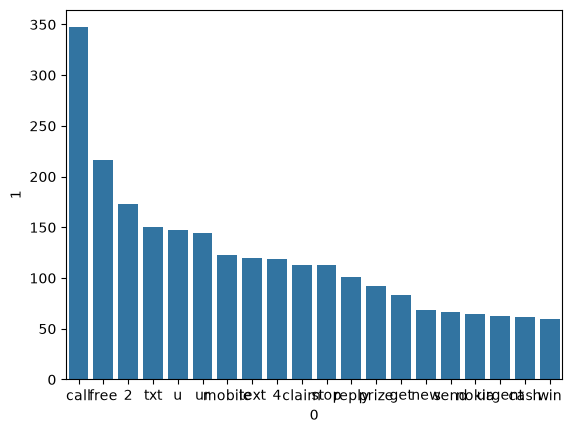

In [75]:
sns.barplot(x=df_spam[0],y=df_spam[1])

<Axes: xlabel='0', ylabel='1'>

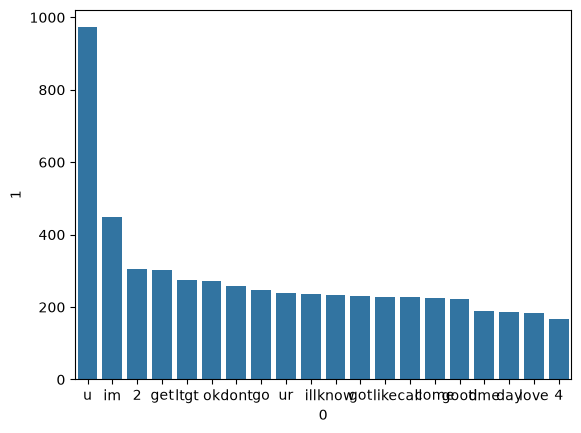

In [76]:
sns.barplot(x=df_ham[0],y=df_ham[1])